# What does the EMG encode: position, velocity or acceleration? And how do we correlate 16 channels with 20 joints over time?

emg2pose is a **regression** problem (continuous joint angles), not gesture classification. A recurring intuition
is that muscles do not encode *where* a finger is but *how it is changing*. This notebook tests that with three
complementary tools, all chosen because they handle **many channels × many joints × time**:

1. **The physics in one line**, and what it predicts.
2. **Encoding models** (kinematics → EMG): which description of the movement (position, velocity, acceleration,
   signed or split into "flexing" vs "extending") best explains each electrode? The EMG analogue of tuning curves
   in motor cortex.
3. **Decoding models with lags** (EMG → kinematics, a *temporal response function*): how much of the position,
   velocity and acceleration of each pose PC can be read out, and from which electrodes and delays.
4. **Multiple coherence**: the frequency-resolved version of R². At which *movement* frequencies do the 16
   channels jointly explain the kinematics?
5. **Muscle synergies vs kinematic synergies**: how many dimensions does the EMG itself have, compared with the pose?
6. A **menu of methods** for EMG ↔ angle correlation and when to use each.

To keep things readable we describe the pose with its **first 8 principal components** (90 % of the variance, see
`joint_space_manifold.ipynb`) instead of 20 angles: this is the same compact representation the project proposes.
Data: mini dataset, both hands pooled, `unconstrained` excluded (its EMG is at the noise floor).

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/rodri/projects/emg2poseneuromatch/semg2pose/.venv/bin/python


## 1. The physics, and what it predicts

A finger joint obeys Newton's law for rotation. Muscle torque τ (from the activation the EMG measures, smoothed
by the muscle's own dynamics) balances

$$\tau(t) \;=\; \underbrace{I\,\ddot\theta}_{\text{inertia}} \;+\; \underbrace{B\,\dot\theta}_{\text{damping}} \;+\; \underbrace{K(\theta-\theta_0)}_{\text{stiffness / passive elasticity}} \;+\; \text{external loads}$$

- **Acceleration term**: fingers are light, so it matters only in fast, ballistic movements (flicks, snaps). There it
  produces the classic **triphasic** pattern: an agonist burst to accelerate, an antagonist burst to brake, a second
  agonist burst.
- **Velocity term**: tissues are viscous; moving at a speed needs ongoing activity.
- **Position term**: holding a finger away from its rest posture needs tonic activity against passive elasticity and
  the antagonist. So **position is encoded too**, especially for held postures.
- **Muscles only pull.** Flexing is done by flexors (palm side), extending by extensors (back). So the EMG of one
  electrode should depend on *rectified* quantities: "how fast is this joint flexing" and "how fast is it extending"
  are two separate inputs, not one signed number.
- **Co-contraction** (flexors and extensors active together, to stiffen the joint) adds activity that is not
  linked to any movement at all.

**Prediction**: the EMG envelope should be explained by a mixture of position and velocity, with velocity entering
in a rectified, agonist/antagonist way; acceleration should add a little; and the sign of the movement should be
readable only from the *balance* between electrode sectors.

**Link to the models.** This is exactly why the pretrained vemg2pose **tracking** model predicts *velocities* and
integrates them from a known starting pose, and why it beats the **regression** model (EMG only) by ~4° on a held-out
user (`pipeline_overview.ipynb`). EMG is a good velocity/effort sensor and a mediocre absolute-position sensor.

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.decomposition import NMF

from semg2pose.data import FS, JOINT_NAMES, download_mini_dataset, list_sessions, load_session
from semg2pose.signals import log_envelope, bandpass, rms_envelope

warnings.filterwarnings("ignore")
DATASET_DIR = download_mini_dataset()
plt.rcParams["figure.dpi"] = 100

STEP = 40                 # 2 kHz -> 50 Hz
FS_L = FS // STEP
LEAD = 3                  # EMG leads movement by ~60 ms = 3 samples at 50 Hz
K_PC = 8                  # pose PCs used as the compact pose description
DERIVS = ["position", "velocity", "acceleration"]

Dataset already downloaded: /home/rodri/emg2pose_dataset_mini


## 2. Data: EMG envelopes and pose PCs with their derivatives

- **EMG**: 20-450 Hz band-pass → 50 ms moving RMS → log, per channel, at 50 Hz (as in `emg_angle_correlation.ipynb`).
- **Kinematics**: Savitzky-Golay fits on the 2 kHz angles (cubic, 150 ms window) give angle, velocity and
  acceleration without amplifying noise; then down to 50 Hz and projected onto the first 8 pose PCs.

In [3]:
sessions = list_sessions(DATASET_DIR)
recs = []
for _, row in sessions.iterrows():
    if row.stage == "unconstrained":
        continue
    emg, angles, ok, meta = load_session(row.path)
    env = log_envelope(emg, band=(20, 450), window_s=0.05)[::STEP]
    lin_env = rms_envelope(bandpass(emg, 20, 450), window_s=0.1)[::STEP]       # linear, for NMF
    kin = {d: signal.savgol_filter(angles, 301, 3, deriv=i, delta=1 / FS, axis=0)[::STEP]
           for i, d in enumerate(DERIVS)}
    good = ~np.convolve(~ok, np.ones(601), mode="same").astype(bool)[::STEP]  # 150 ms away from IK failures
    recs.append({"stage": row.stage, "side": row.side, "env": env, "lin_env": lin_env, "kin": kin, "ok": good})

pos_all = np.vstack([r["kin"]["position"][r["ok"]] for r in recs])
mu = pos_all.mean(0)
_, s, Vt = np.linalg.svd(pos_all - mu, full_matrices=False)
W = Vt[:K_PC]                                                                 # (8, 20)
ev = s ** 2 / (s ** 2).sum()
for r in recs:                                                                # project every derivative on the PCs
    r["z"] = {"position": (r["kin"]["position"] - mu) @ W.T,
              "velocity": r["kin"]["velocity"] @ W.T,
              "acceleration": r["kin"]["acceleration"] @ W.T}
print(f"{len(recs)} recordings, {sum(r['ok'].sum() for r in recs) / FS_L / 60:.1f} valid min; "
      f"first {K_PC} PCs = {100 * ev[:K_PC].sum():.0f} % of pose variance")

28 recordings, 24.7 valid min; first 8 PCs = 91 % of pose variance


## 3. Encoding models: which description of the movement explains each electrode?

For every channel c we fit a ridge regression `envelope_c(t) ≈ f(kinematics at t + 60 ms)` with different
kinematic descriptions (all built from the 8 pose PCs), and score it with **blocked 5-fold CV** (contiguous blocks
within each recording). "Rectified" means each signed variable x is split into two non-negative inputs,
max(x, 0) and max(−x, 0): "moving one way" and "moving the other way", which is how agonist/antagonist muscles see it.

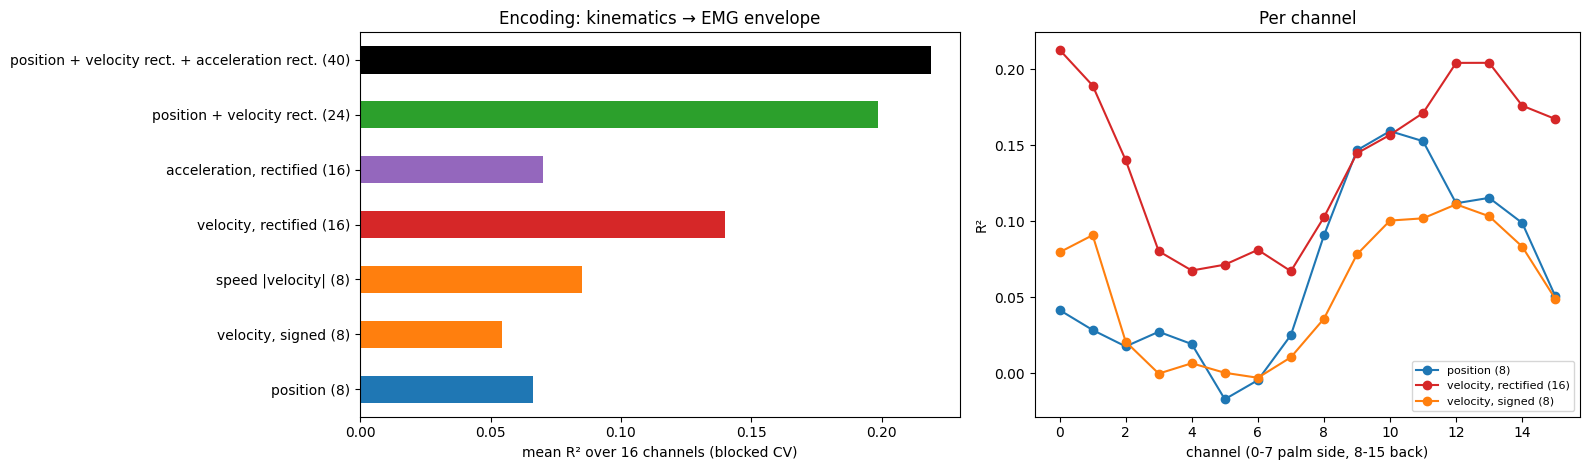

,mean R²
position (8),0.066
"velocity, signed (8)",0.054
speed |velocity| (8),0.085
"velocity, rectified (16)",0.140
"acceleration, rectified (16)",0.070
position + velocity rect. (24),0.198
position + velocity rect. + acceleration rect. (40),0.219


In [4]:
def rect(x):
    return np.hstack([np.clip(x, 0, None), np.clip(-x, 0, None)])


DESCRIPTIONS = {
    "position (8)": lambda z: z["position"],
    "velocity, signed (8)": lambda z: z["velocity"],
    "speed |velocity| (8)": lambda z: np.abs(z["velocity"]),
    "velocity, rectified (16)": lambda z: rect(z["velocity"]),
    "acceleration, rectified (16)": lambda z: rect(z["acceleration"]),
    "position + velocity rect. (24)": lambda z: np.hstack([z["position"], rect(z["velocity"])]),
    "position + velocity rect. + acceleration rect. (40)":
        lambda z: np.hstack([z["position"], rect(z["velocity"]), rect(z["acceleration"])]),
}


def ridge_cv(X, Y, folds, lam=10.0):
    P = np.zeros_like(Y)
    for k in range(5):
        tr, te = folds != k, folds == k
        m, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
        A, B = (X[tr] - m) / sd, (X[te] - m) / sd
        ym = Y[tr].mean(0)
        Wr = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (Y[tr] - ym))
        P[te] = B @ Wr + ym
    return 1 - ((Y - P) ** 2).sum(0) / ((Y - Y.mean(0)) ** 2).sum(0)


def encoding_data(desc):
    Xs, Ys, Fs = [], [], []
    for r in recs:
        T = len(r["ok"])
        t = np.arange(T - LEAD)
        keep = r["ok"][t] & r["ok"][t + LEAD]
        Xs.append(desc({k: v[t + LEAD] for k, v in r["z"].items()})[keep])   # kinematics 60 ms later
        Ys.append(r["env"][t][keep])                                       # EMG now
        Fs.append((np.arange(T - LEAD) * 5 // T)[keep])
    return np.vstack(Xs), np.vstack(Ys), np.concatenate(Fs)


enc = {}
for name, desc in DESCRIPTIONS.items():
    X, Y, folds = encoding_data(desc)
    enc[name] = ridge_cv(X, Y, folds)
enc = pd.DataFrame(enc)                                   # (16 channels, descriptions)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
enc.mean().plot.barh(ax=ax1, color=["tab:blue", "tab:orange", "tab:orange", "tab:red", "tab:purple", "tab:green", "k"])
ax1.set_xlabel("mean R² over 16 channels (blocked CV)"); ax1.set_title("Encoding: kinematics → EMG envelope")
for col, st in [("position (8)", "tab:blue"), ("velocity, rectified (16)", "tab:red"), ("velocity, signed (8)", "tab:orange")]:
    ax2.plot(range(16), enc[col], "o-", color=st, label=col)
ax2.set_xlabel("channel (0-7 palm side, 8-15 back)"); ax2.set_ylabel("R²"); ax2.legend(fontsize=8)
ax2.set_title("Per channel")
plt.tight_layout(); plt.show()
enc.mean().round(3).to_frame("mean R²")

**Reading it.**

- **Rectified velocity is the best single description** (R² ≈ 0.14), well above *signed* velocity (≈ 0.05) and
  position (≈ 0.07). Splitting "flexing" from "extending" matters: an electrode over the flexors responds to
  flexion and is silent (or only co-contracting) during extension, and a linear model on signed velocity cannot
  express that.
- **Position and velocity add up** (≈ 0.20 together), and acceleration adds a little more (≈ 0.22). So the answer
  to "position or change?" is **both, with velocity (split by direction) the largest part**, exactly as the
  physics predicts.
- **Per channel** (right panel): electrodes on the **back of the wrist (8-14)** carry as much position as velocity
  information, while **palm-side electrodes (3-7)** carry almost no position information and respond mainly to
  movement. The ulnar edge (0-1) is the most velocity-tuned. A plausible reading: the extensors work tonically to
  hold the fingers open/extended against the flexors' passive pull, so their level tracks posture.
- Absolute R² values are modest: the envelope also contains co-contraction, wrist activity (not in the labels),
  noise, and nonlinear effects.

**Unique contribution of each derivative**: how much R² is lost when one ingredient is removed from the full model
(position + rectified velocity + rectified acceleration).

In [5]:
full = DESCRIPTIONS["position + velocity rect. + acceleration rect. (40)"]
drop = {"without position": lambda z: np.hstack([rect(z["velocity"]), rect(z["acceleration"])]),
        "without velocity": lambda z: np.hstack([z["position"], rect(z["acceleration"])]),
        "without acceleration": lambda z: np.hstack([z["position"], rect(z["velocity"])])}
X, Y, folds = encoding_data(full)
r2_full = ridge_cv(X, Y, folds).mean()
unique = {}
for name, desc in drop.items():
    X, Y, folds = encoding_data(desc)
    unique[name.replace("without ", "")] = r2_full - ridge_cv(X, Y, folds).mean()
print(f"full model mean R² = {r2_full:.3f}")
pd.Series(unique, name="R² lost when removed (unique contribution)").round(3).to_frame()

full model mean R² = 0.219


,R² lost when removed (unique contribution)
position,0.062
velocity,0.083
acceleration,0.021


Velocity has the largest unique contribution, position is close behind, acceleration is small but non-zero
(fast flicks and snaps).

## 4. Decoding with lags (temporal response function): what can be read out from the EMG?

The other direction: predict each pose PC's position, velocity and acceleration at time t from the 16 envelopes at
t, t−20 ms, …, t−300 ms (8 lags × 16 channels = 128 features). This is a **multivariate temporal response
function** (mTRF), the standard tool in EEG for relating a multichannel signal to a continuous stimulus or behaviour
over time (Crosse et al. 2016). The weights over lags and channels can be read as a filter: *which electrodes, how
long before*.

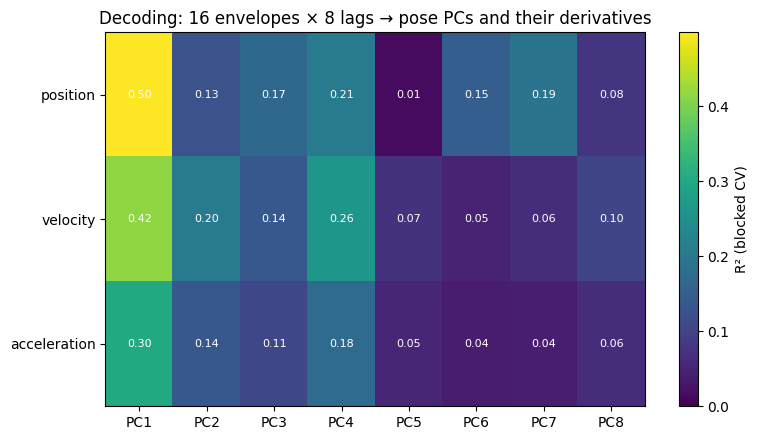

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
position,0.498,0.127,0.169,0.207,0.015,0.149,0.192,0.076
velocity,0.415,0.205,0.137,0.263,0.074,0.050,0.065,0.104
acceleration,0.303,0.137,0.107,0.175,0.053,0.038,0.042,0.065


In [6]:
LAGS = [0, 1, 2, 3, 5, 8, 11, 15]       # samples at 50 Hz: 0 ... 300 ms into the past


def with_lags(X, lags):
    return np.hstack([X if l == 0 else np.vstack([np.repeat(X[:1], l, axis=0), X[:-l]]) for l in lags])


Xd, Fd, Zd = [], [], {d: [] for d in DERIVS}
for r in recs:
    T = len(r["ok"])
    keep = r["ok"]
    Xd.append(with_lags(r["env"], LAGS)[keep])
    Fd.append((np.arange(T) * 5 // T)[keep])
    for d in DERIVS:
        Zd[d].append(r["z"][d][keep])
Xd, Fd = np.vstack(Xd), np.concatenate(Fd)
dec = pd.DataFrame({d: ridge_cv(Xd, np.vstack(Zd[d]), Fd) for d in DERIVS}, index=[f"PC{i + 1}" for i in range(K_PC)])

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(dec.T.values, cmap="viridis", vmin=0, vmax=max(0.05, dec.values.max()), aspect="auto")
for i in range(len(DERIVS)):
    for j in range(K_PC):
        ax.text(j, i, f"{dec.values[j, i]:.2f}", ha="center", va="center", color="w", fontsize=8)
ax.set_xticks(range(K_PC), dec.index); ax.set_yticks(range(3), DERIVS)
plt.colorbar(im, ax=ax, label="R² (blocked CV)")
ax.set_title("Decoding: 16 envelopes × 8 lags → pose PCs and their derivatives")
plt.tight_layout(); plt.show()
dec.round(3).T

**Reading it.** With 300 ms of history, a linear decoder reads PC1 (open/close) best: position R² ≈ 0.5, velocity
≈ 0.4, even acceleration ≈ 0.3. Higher PCs (individual fingers, thumb) are much weaker, consistent with what the
pretrained network achieves (`compression_tolerance.ipynb` §5). Position is *decodable* even though the
envelope *encodes* velocity more strongly: with a history of activity, the decoder can effectively integrate.

**The temporal response function of PC1** (open/close the hand): ridge weights fitted on all data, for its velocity
and for its position, shown as lag × channel. Red = more activity at that electrode and delay predicts a larger
PC1 value (PCA signs are arbitrary, so what matters is whether a channel's weights change sign across lags).

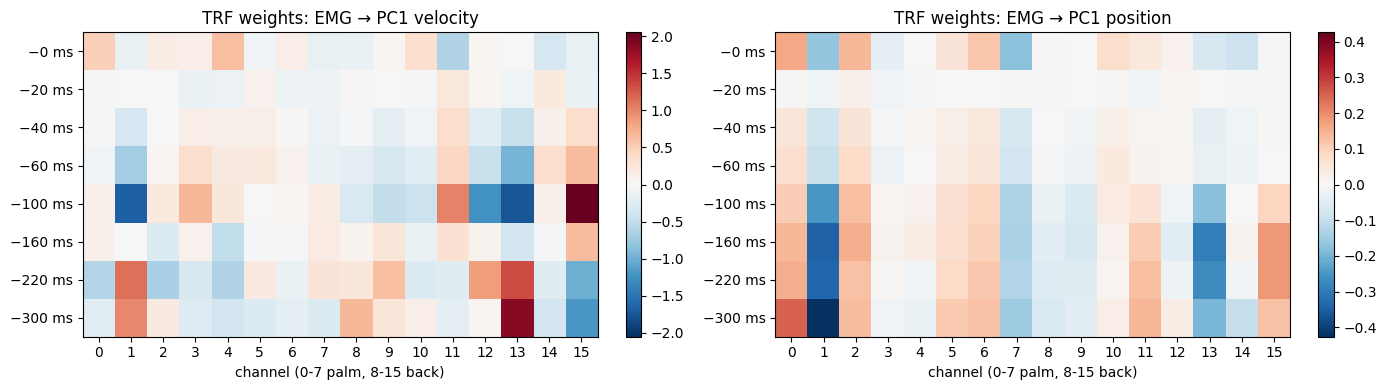

In [7]:
def trf(target):
    Y = np.concatenate([z[:, 0] for z in Zd[target]])
    m, sd = Xd.mean(0), Xd.std(0) + 1e-9
    A = (Xd - m) / sd
    w = np.linalg.solve(A.T @ A + 10 * np.eye(A.shape[1]), A.T @ (Y - Y.mean()))
    return w.reshape(len(LAGS), 16)


fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, target in zip(axs, ["velocity", "position"]):
    w = trf(target)
    lim = np.abs(w).max()
    im = ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_yticks(range(len(LAGS)), [f"−{l * 20} ms" for l in LAGS])
    ax.set_xticks(range(16)); ax.set_xlabel("channel (0-7 palm, 8-15 back)")
    ax.set_title(f"TRF weights: EMG → PC1 {target}")
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

**Reading it.** The two filters have different *temporal* shapes. The **velocity** filter is **biphasic over
lags**: on the key electrodes (1, 11, 13, 15) the weight at −100 ms has the opposite sign of the weight at −220 to
−300 ms, i.e. the decoder takes a **difference between recent and older activity**: a temporal derivative. The
**position** filter keeps **the same sign across lags**: a running sum (integration). Spatially both rely on a few
sectors with opposite signs (e.g. channel 1 vs 0/2, channel 13 vs 15): the agonist-antagonist balance.

## 5. Multiple coherence: at which movement frequencies do EMG and kinematics share information?

**Coherence** is a correlation computed separately at every frequency: 1 means the two signals are perfectly
linearly related at that frequency (up to a fixed gain and delay), 0 means unrelated. **Multiple coherence**
generalises it to many inputs: at each frequency, the fraction of the target's power that the best linear
combination of *all 16 channels* can explain. It is the frequency-resolved version of the decoder's R², and
handles delays automatically (no need to choose lags).

We estimate cross-spectra with Welch's method (2.56 s Hann windows, 50 % overlap) inside IK-failure-free stretches,
pooling all windows of all recordings (so the estimate's positive bias, about #channels / #windows, is small).

660 windows of 2.56 s


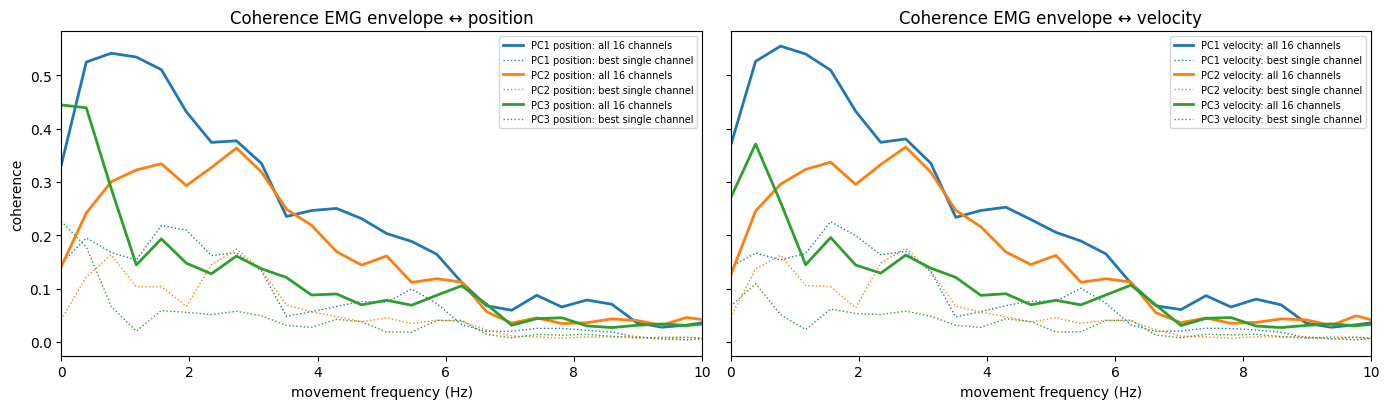

In [8]:
NPS = 128
win = signal.windows.hann(NPS)
freqs = np.fft.rfftfreq(NPS, 1 / FS_L)
targets = {f"PC{k + 1} {d}": (d, k) for d in ["position", "velocity"] for k in range(3)}
Sxx = np.zeros((len(freqs), 16, 16), complex)
Sxy = {t: np.zeros((len(freqs), 16), complex) for t in targets}
Syy = {t: np.zeros(len(freqs)) for t in targets}
n_win = 0
for r in recs:
    ok = r["ok"]
    edges = np.flatnonzero(np.diff(np.r_[0, ok.astype(int), 0]))
    for a, b in zip(edges[::2], edges[1::2]):
        for st in range(a, b - NPS + 1, NPS // 2):
            seg = slice(st, st + NPS)
            Xf = np.fft.rfft(signal.detrend(r["env"][seg], axis=0) * win[:, None], axis=0)      # (F, 16)
            Sxx += Xf[:, :, None] * Xf[:, None, :].conj()
            for t, (d, k) in targets.items():
                yf = np.fft.rfft(signal.detrend(r["z"][d][seg, k]) * win)
                Sxy[t] += Xf * yf[:, None].conj()
                Syy[t] += np.abs(yf) ** 2
            n_win += 1
print(f"{n_win} windows of {NPS / FS_L:.2f} s")

mcoh, pcoh = {}, {}
diag = np.real(np.einsum("fii->fi", Sxx))
for t in targets:
    sol = np.linalg.solve(Sxx, Sxy[t][:, :, None])[:, :, 0]                 # Sxx^-1 Sxy
    mcoh[t] = np.real(np.einsum("fi,fi->f", Sxy[t].conj(), sol)) / Syy[t]
    pcoh[t] = (np.abs(Sxy[t]) ** 2 / (diag * Syy[t][:, None])).max(1)        # best single channel

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, d in zip(axs, ["position", "velocity"]):
    for k, col in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
        t = f"PC{k + 1} {d}"
        ax.plot(freqs, mcoh[t], color=col, lw=2, label=f"{t}: all 16 channels")
        ax.plot(freqs, pcoh[t], color=col, lw=1, ls=":", label=f"{t}: best single channel")
    ax.set_xlim(0, 10); ax.set_xlabel("movement frequency (Hz)"); ax.set_title(f"Coherence EMG envelope ↔ {d}")
    ax.legend(fontsize=7)
axs[0].set_ylabel("coherence")
plt.tight_layout(); plt.show()

**Reading it.**

- EMG and movement are coupled only at **slow movement frequencies**: multiple coherence ≈ 0.5 for PC1 between
  ~0.4 and 2 Hz, decaying to ≈ 0 by ~7 Hz. Above that the kinematics have almost no power anyway.
- **All 16 channels together explain 2-3× more than the best single channel** (solid vs dotted): the information is
  *distributed* across the ring, which is why single correlations look weak (`emg_angle_correlation.ipynb`).
- **The position and velocity panels are almost identical, and that is a theorem, not a coincidence.** Velocity is
  the derivative of position, and differentiation is a linear filter (gain ∝ frequency, 90° phase shift).
  Coherence is unchanged by any linear filter applied to one of the signals. So *for linear models*, "does the EMG
  encode position or velocity?" has no frequency-by-frequency answer: the difference is only a gain and a delay.
  The question becomes meaningful through **nonlinearity** (rectification, as in section 3: muscles only pull) and
  through **which frequencies dominate the error metric** (position errors are dominated by slow drifts and offsets,
  where EMG says little; that is why tracking from a known start beats pure regression).

## 6. Muscle synergies vs kinematic synergies: how many dimensions does the EMG have?

In motor neuroscience, **muscle synergies** (d'Avella, Bizzi and colleagues) are found by factorising multi-muscle
EMG envelopes with **non-negative matrix factorisation** (NMF): EMG(t) ≈ Σ_k c_k(t) · w_k, with non-negative
spatial patterns w_k (which electrodes work together) and activations c_k(t). Non-negativity matches the physiology
(activity cannot be negative). The usual criterion is the number of synergies reaching 90 % *variance accounted for*
(VAF, computed without centring). We compare with the PCA of the envelopes (centred) and with the PCA of the pose.

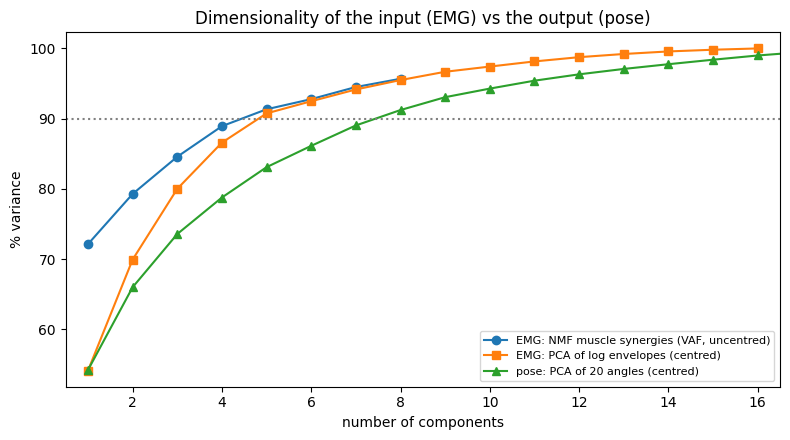

NMF synergies for 90 % VAF: 5;  EMG PCA for 90 %: 5;  pose PCA for 90 %: 8


In [9]:
E = np.vstack([r["lin_env"][r["ok"]] for r in recs])
E = E / E.std(0)                                          # unit variance per channel (standard in synergy analysis)
vaf, nmf_models = [], {}
for k in range(1, 9):
    nmf = NMF(n_components=k, init="nndsvda", max_iter=500, random_state=0)
    C = nmf.fit_transform(E)
    vaf.append(1 - ((E - C @ nmf.components_) ** 2).sum() / (E ** 2).sum())
    nmf_models[k] = nmf
se = np.linalg.svd(np.log1p(E) - np.log1p(E).mean(0), compute_uv=False) ** 2
cum_emg = np.cumsum(se) / se.sum()
cum_pose = np.cumsum(ev)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, 9), 100 * np.array(vaf), "o-", label="EMG: NMF muscle synergies (VAF, uncentred)")
ax.plot(range(1, 17), 100 * cum_emg, "s-", label="EMG: PCA of log envelopes (centred)")
ax.plot(range(1, 21), 100 * cum_pose, "^-", label="pose: PCA of 20 angles (centred)")
ax.axhline(90, color="gray", ls=":")
ax.set_xlabel("number of components"); ax.set_ylabel("% variance"); ax.set_xlim(0.5, 16.5)
ax.legend(fontsize=8); ax.set_title("Dimensionality of the input (EMG) vs the output (pose)")
plt.tight_layout(); plt.show()
n_syn = int(np.searchsorted(vaf, 0.9) + 1)
print(f"NMF synergies for 90 % VAF: {n_syn};  EMG PCA for 90 %: {np.searchsorted(cum_emg, 0.9) + 1};  "
      f"pose PCA for 90 %: {np.searchsorted(cum_pose, 0.9) + 1}")

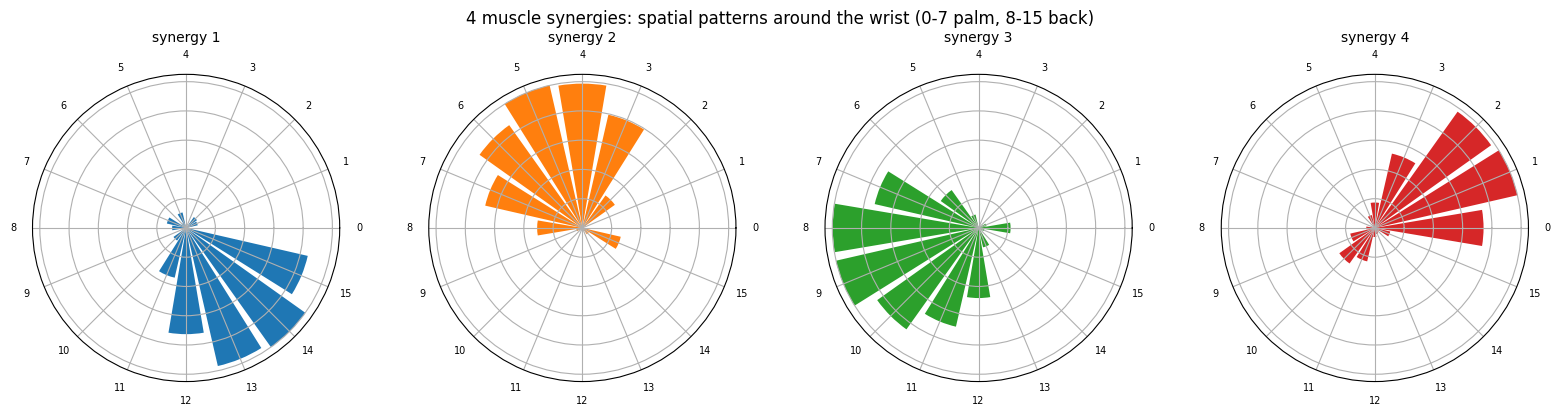

In [10]:
k_show = 4
Wsyn = nmf_models[k_show].components_
ang_c = 2 * np.pi * np.arange(16) / 16
fig, axs = plt.subplots(1, k_show, figsize=(4 * k_show, 4), subplot_kw={"projection": "polar"})
Csyn = nmf_models[k_show].transform(E)
for k, ax in enumerate(axs):
    ax.bar(ang_c, Wsyn[k] / Wsyn[k].max(), width=2 * np.pi / 16 * 0.85, color=f"C{k}")
    ax.set_xticks(ang_c, [str(c) for c in range(16)], fontsize=7); ax.set_yticklabels([])
    ax.set_title(f"synergy {k + 1}", fontsize=10)
fig.suptitle(f"{k_show} muscle synergies: spatial patterns around the wrist (0-7 palm, 8-15 back)")
plt.tight_layout(); plt.show()

**Reading it.**

- The synergies are **contiguous sectors of the ring**, i.e. muscle groups: back-ulnar (12-15: wrist/finger
  extensors ECU, ED), palm (3-7: finger and thumb flexors FDS, FPL), back-radial (8-11: thumb muscles APL/EPB, EPL),
  and ulnar-palm (0-2: FCU and nearby flexors).
- **5 synergies reach 90 % VAF; the PCA of the log envelopes also needs 5 components; the pose needs 8.** At the
  level of envelopes, the **input is lower-dimensional than the output**. Since a decoder cannot create
  information, the pose dimensions that are reliably decodable from envelope-like features are bounded by a handful.
  (The raw EMG has more structure: fine spatial/spectral detail that the network exploits, see
  `spectral_spatial_fingerprints.ipynb` §5. That is why the network does better than these linear analyses.)
- For the presentation, this is a clean neuro-motivated argument for a pose bottleneck: **muscle synergies (~5)
  ↔ kinematic synergies (~3 effective, 8 for 90 %)**.

## 7. A menu of methods for "16 channels × 20 joints × time"

| method | question it answers | handles time how | multivariate? | used here |
|---|---|---|---|---|
| lagged pairwise correlation | which channel goes with which joint, at which delay | explicit lag sweep | no (pairs) | `emg_angle_correlation.ipynb` |
| **CCA** (+ lagged CCA) | the main shared "modes" between the channel set and the joint set | one lag, or stacked lags | yes, both sides | `emg_angle_correlation.ipynb` |
| PLS / reduced-rank regression | like CCA but focused on predicting the joints; the rank is a bottleneck | stacked lags | yes | (natural next step; rank = latent size k!) |
| **encoding model** (kinematics → EMG) | what each electrode "cares about": position, velocity, direction... | lead/lag | yes (many regressors) | section 3 |
| **mTRF / lagged decoding** (EMG → kinematics) | how much is readable, from which electrodes and delays | lags as features | yes | section 4 |
| **(multiple) coherence** | at which *movement frequencies* they are linked; no lag choice needed | frequency domain | yes (multiple coherence) | section 5 |
| time-frequency features + any of the above | does EMG spectral content add information | bands as features | yes | `spectral_spatial_fingerprints.ipynb` |
| mutual information / nonlinear decoders | relations a linear model misses | windows | yes | the pretrained network is the upper bound |
| Granger causality / transfer entropy | directed influence (EMG → movement and back via feedback) | autoregressive models | yes | (not needed: the 60 ms lead already shows direction) |

**Moving to the time-frequency domain** helps in two distinct ways, which are easy to mix up: (i) EMG frequency
(20-500 Hz) → band features that act as a spatial zoom (`spectral_spatial_fingerprints.ipynb`); (ii) *movement*
frequency (0-10 Hz) → coherence, which turns "correlation across time with unknown delays" into one clean curve
per frequency (section 5). For the project, the most useful combination is **decoding/CCA towards pose PCs**: it
directly measures which compact pose dimensions the EMG can see.

## 8. Summary

In [11]:
print("Encoding (kinematics → EMG), mean R² over channels:")
print(enc.mean().round(3).to_string())
print("\nUnique contribution:", {k: round(v, 3) for k, v in unique.items()})
print("\nDecoding (EMG → pose PCs) R²:")
print(dec.round(2).T.to_string())
band = (freqs > 0.2) & (freqs < 2)
print("\nMean multiple coherence 0.2-2 Hz:", {t: round(float(mcoh[t][band].mean()), 2) for t in mcoh})
print(f"\nNMF synergies for 90 % VAF: {n_syn}")

Encoding (kinematics → EMG), mean R² over channels:
position (8)                                           0.066
velocity, signed (8)                                   0.054
speed |velocity| (8)                                   0.085
velocity, rectified (16)                               0.140
acceleration, rectified (16)                           0.070
position + velocity rect. (24)                         0.198
position + velocity rect. + acceleration rect. (40)    0.219

Unique contribution: {'position': 0.062, 'velocity': 0.083, 'acceleration': 0.021}

Decoding (EMG → pose PCs) R²:
               PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8
position      0.50  0.13  0.17  0.21  0.01  0.15  0.19  0.08
velocity      0.42  0.20  0.14  0.26  0.07  0.05  0.06  0.10
acceleration  0.30  0.14  0.11  0.18  0.05  0.04  0.04  0.06

Mean multiple coherence 0.2-2 Hz: {'PC1 position': 0.51, 'PC2 position': 0.3, 'PC3 position': 0.24, 'PC1 velocity': 0.51, 'PC2 velocity': 0.3, 'PC3 velocity': 0.

**Answers**

1. **Classification or regression?** emg2pose and the proposal are **regression**: continuous joint angles over
   time. Gesture classification would be a coarser, easier problem.
2. **Does the EMG encode position or change?** Both. In encoding models, **direction-split (rectified) velocity**
   explains the most, position adds almost as much, acceleration a little. Back-of-wrist electrodes carry posture,
   palm-side electrodes mostly movement.
3. **Where do derivatives come in?** (i) Physically: torque = inertia·acceleration + damping·velocity +
   stiffness·position. (ii) In the decoders: the velocity filter is a temporal *difference* of EMG activity, the
   position filter a running *sum*. (iii) In the benchmark: the tracking model predicts velocity and integrates
   from a known start, which is why it beats regression by ~4° on a new person. (iv) In the frequency domain,
   position and velocity are the same signal up to a gain and phase, so linear coherence cannot tell them apart.
4. **How to correlate many channels with many joints over time?** Reduce the joints to pose PCs, then use
   lagged decoding (mTRF), CCA/PLS, and multiple coherence. All three agree: one dominant shared mode (open/close),
   a few weaker ones, coupling only below ~5 Hz, information distributed across electrodes.
5. **Dimensionality**: EMG envelopes ~5 dimensions (synergies), pose ~8 for 90 %, decodable pose PCs a handful.
   Consistent with a compact pose bottleneck.